# Bangalore Sales Map (GeoPandas)

This notebook visualizes `FOOD_ANALYSIS` sales by Bangalore area on a real map using pandas, GeoPandas, matplotlib, and contextily.

Area coordinates are approximate and used for visualization only.

In [17]:
import os

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv()

connection_url = URL.create(
    "oracle+oracledb",
    username=os.environ["ORACLE_USER"],
    password=os.environ["ORACLE_PASSWORD"],
    host="localhost",
    port=1522,
    query={"service_name": "FREEPDB1"},
)
engine = create_engine(connection_url)


In [18]:
area_sales = pd.read_sql(
    """
    SELECT
        c.area,
        COUNT(DISTINCT c.customer_id) AS total_customers,
        COUNT(o.order_id) AS total_orders,
        SUM(o.order_amount) AS total_sales
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY c.area
    ORDER BY total_sales DESC
    """,
    engine,
)
area_sales

,area,total_customers,total_orders,total_sales
0,Whitefield,15,69,29390
1,HSR Layout,17,72,29370
2,Bellandur,12,66,26410
3,Electronic City,11,64,26005
4,BTM Layout,13,66,25885
5,Koramangala,12,53,25585
6,Indiranagar,11,52,22025
7,JP Nagar,10,47,18180
8,Rajajinagar,7,44,16290
9,Jayanagar,5,33,12705


In [19]:
# Approximate coordinates for Bangalore areas present in the dataset.
coords = pd.DataFrame([
    {"area": "Whitefield", "lat": 12.9698, "lon": 77.7499},
    {"area": "HSR Layout", "lat": 12.9121, "lon": 77.6446},
    {"area": "Bellandur", "lat": 12.9260, "lon": 77.6762},
    {"area": "Electronic City", "lat": 12.8399, "lon": 77.6770},
    {"area": "BTM Layout", "lat": 12.9166, "lon": 77.6101},
    {"area": "Koramangala", "lat": 12.9352, "lon": 77.6245},
    {"area": "Indiranagar", "lat": 12.9719, "lon": 77.6412},
    {"area": "JP Nagar", "lat": 12.9063, "lon": 77.5857},
    {"area": "Rajajinagar", "lat": 12.9982, "lon": 77.5530},
    {"area": "Jayanagar", "lat": 12.9308, "lon": 77.5838},
    {"area": "Marathahalli", "lat": 12.9591, "lon": 77.6974},
    {"area": "Malleshwaram", "lat": 13.0031, "lon": 77.5643},
])

map_df = area_sales.merge(coords, on="area", how="left")
missing = map_df[map_df["lat"].isna()]
if not missing.empty:
    print("Missing coordinates for:", missing["area"].tolist())
map_df

,area,total_customers,total_orders,total_sales,lat,lon
0,Whitefield,15,69,29390,12.9698,77.7499
1,HSR Layout,17,72,29370,12.9121,77.6446
2,Bellandur,12,66,26410,12.9260,77.6762
3,Electronic City,11,64,26005,12.8399,77.6770
4,BTM Layout,13,66,25885,12.9166,77.6101
5,Koramangala,12,53,25585,12.9352,77.6245
6,Indiranagar,11,52,22025,12.9719,77.6412
7,JP Nagar,10,47,18180,12.9063,77.5857
8,Rajajinagar,7,44,16290,12.9982,77.5530
9,Jayanagar,5,33,12705,12.9308,77.5838


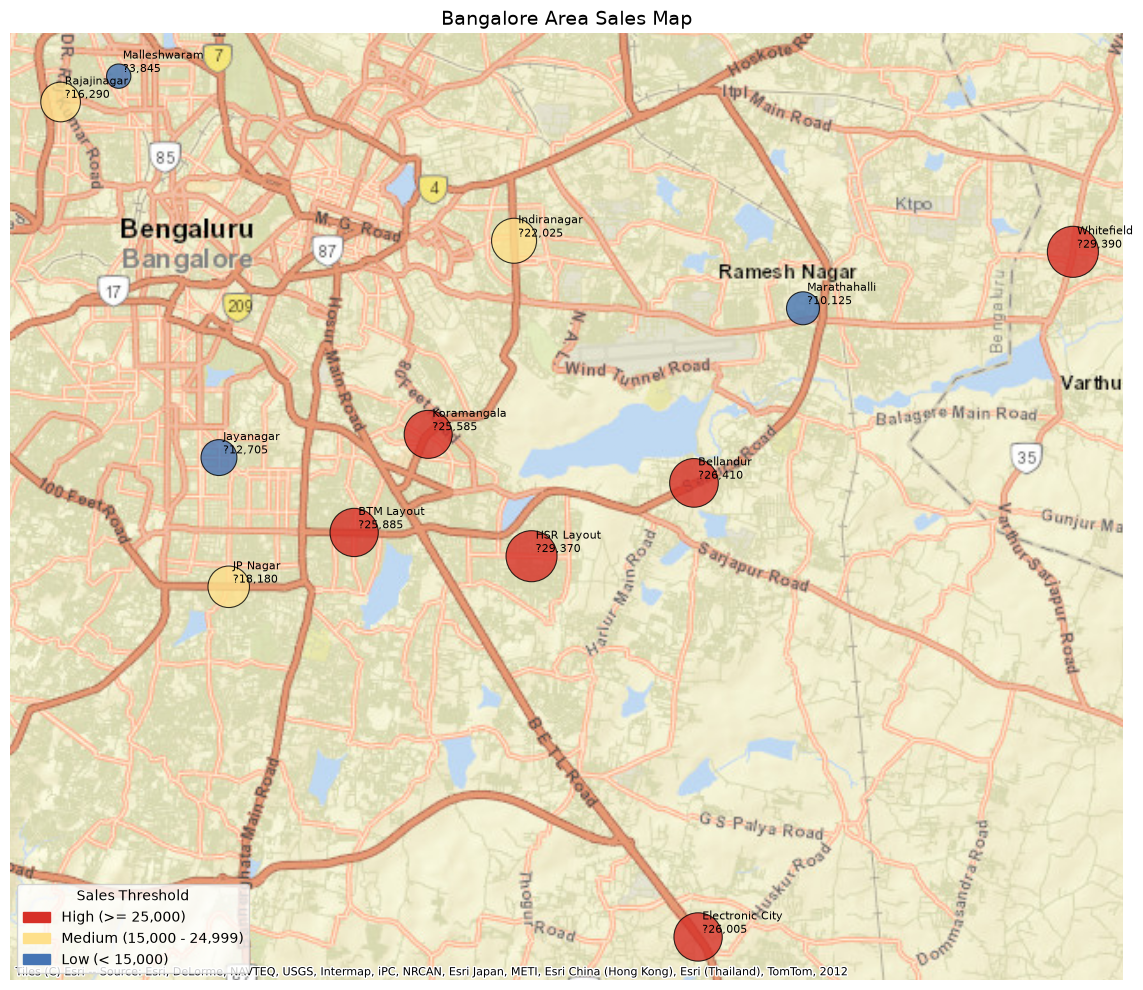

In [20]:
import matplotlib.patches as mpatches

gdf = gpd.GeoDataFrame(
    map_df,
    geometry=gpd.points_from_xy(map_df["lon"], map_df["lat"]),
    crs="EPSG:4326",
).to_crs(epsg=3857)

def sales_threshold(amount):
    if amount >= 25000:
        return "High (>= 25,000)"
    if amount >= 15000:
        return "Medium (15,000 - 24,999)"
    return "Low (< 15,000)"

color_map = {
    "High (>= 25,000)": "#d73027",
    "Medium (15,000 - 24,999)": "#fee08b",
    "Low (< 15,000)": "#4575b4",
}

gdf["sales_band"] = gdf["total_sales"].apply(sales_threshold)
gdf["color"] = gdf["sales_band"].map(color_map)

fig, ax = plt.subplots(figsize=(12, 10))
max_sales = gdf["total_sales"].max()
sizes = (gdf["total_sales"] / max_sales) * 1200 + 150

gdf.plot(
    ax=ax,
    color=gdf["color"],
    markersize=sizes,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.8,
)

for _, row in gdf.iterrows():
    ax.annotate(
        f"{row['area']}\n?{int(row['total_sales']):,}",
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=8,
    )

legend_handles = [
    mpatches.Patch(color=color, label=label) for label, color in color_map.items()
]
ax.legend(handles=legend_handles, title="Sales Threshold", loc="lower left")

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldStreetMap)
ax.set_title("Bangalore Area Sales Map", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.show()
